# Deep Learning Lab 2 - Part 1: CNN, Faster R-CNN and transfer learning on MNIST
Master MBD - Deep Learning - FST Tanger, Université Abdelmalek Essaadi.

This notebook only reads the results produced by the scripts in `src/` (`results/*.json`, `figures/*.png`), so it runs in a few seconds.

In [1]:
import os, sys, json
from pathlib import Path
if Path.cwd().name == "notebooks":      # local nbconvert runs from notebooks/
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import torch
from IPython.display import Image, display
%matplotlib inline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device,
      torch.cuda.get_device_name(0) if device.type == "cuda" else "(CPU used for this lab)")


PyTorch: 2.14.1+cpu | device: cpu (CPU used for this lab)


## 1. MNIST
60 000 training images / 10 000 test images, 28x28 grayscale, 10 balanced classes. Loaded with `torchvision.datasets.MNIST(download=True)`.

In [2]:
from src.data import load_mnist
Xtr, ytr, Xte, yte = load_mnist()
print(Xtr.shape, Xte.shape, Xtr.dtype)
print('class counts:', ytr.sum(0) if ytr.ndim == 2 else __import__('numpy').bincount(ytr))

(60000, 28, 28) (10000, 28, 28) uint8
class counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


## 2. Custom CNN
`Conv(1→32, k3, p1) + ReLU + MaxPool2` → `Conv(32→64, k3, p1) + ReLU + MaxPool2` → `Flatten` → `FC 128 + ReLU + Dropout(0.5)` → `FC 10`. Shapes: 1x28x28 → 32x28x28 → 32x14x14 → 64x14x14 → 64x7x7 → 3136 → 128 → 10.

3x3 kernels with padding 1 keep the size, so the two pooling layers do all the downsampling; two stacked convs already see a 5x5 receptive field with few parameters. Adam (lr=1e-3) with weight decay 1e-4 and dropout 0.5 regularise the model; 5 epochs, batch 256, full 60k/10k split.

In [3]:
from src.models import CNN
from src.utils import count_parameters

m = CNN()
x = torch.randn(1, 1, 28, 28)
for name, layer in m.features.named_children():
    x = layer(x); print(f'{name:9s} {type(layer).__name__:11s} -> {tuple(x.shape)}')
x = m.classifier[0](x); print('flatten    ->', tuple(x.shape))
x = m.classifier[1](x); print('fc1        ->', tuple(x.shape))
print(count_parameters(m))

0         Conv2d      -> (1, 32, 28, 28)
1         ReLU        -> (1, 32, 28, 28)
2         MaxPool2d   -> (1, 32, 14, 14)
3         Conv2d      -> (1, 64, 14, 14)
4         ReLU        -> (1, 64, 14, 14)
5         MaxPool2d   -> (1, 64, 7, 7)
flatten    -> (1, 3136)
fc1        -> (1, 128)
{'params_total': 421642, 'params_trainable': 421642}


In [4]:
display(pd.read_csv('results/results_all.csv').round(4))

,Model,Accuracy,F1,Loss,TrainTime(s),Params,TrainImgs,TestImgs,Epochs,Device
0,CNN,0.9902,0.9901,0.0293,324.9498,421642,60000,10000,5,cpu
1,Faster R-CNN,0.7680,0.7198,NaN,98.2104,18976354,2000,1000,1,cpu
2,VGG16,0.7880,0.7881,NaN,270.5914,134301514,5000,2000,1,cpu
3,AlexNet,0.8665,0.8680,NaN,58.8627,57044810,5000,2000,1,cpu
4,ViT,0.8401,0.8399,NaN,39.1988,139018,20000,10000,3,cpu


device used: cpu


,epoch,train_loss,train_acc,test_loss,test_acc
0,1,0.3116,0.9040,0.0718,0.9760
1,2,0.0913,0.9724,0.0403,0.9866
2,3,0.0680,0.9795,0.0351,0.9884
3,4,0.0549,0.9832,0.0359,0.9883
4,5,0.0475,0.9859,0.0293,0.9902


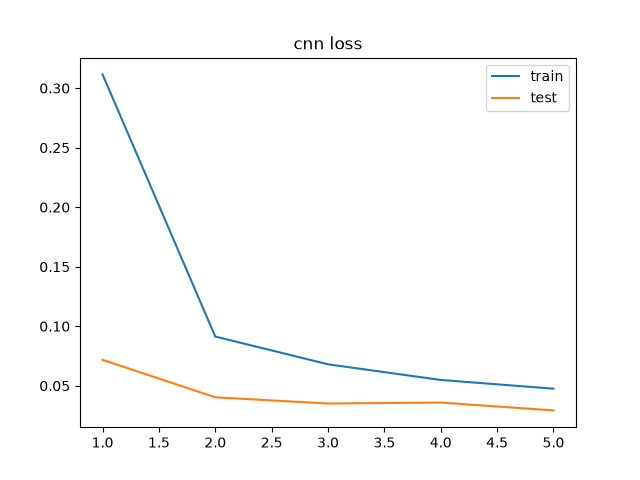

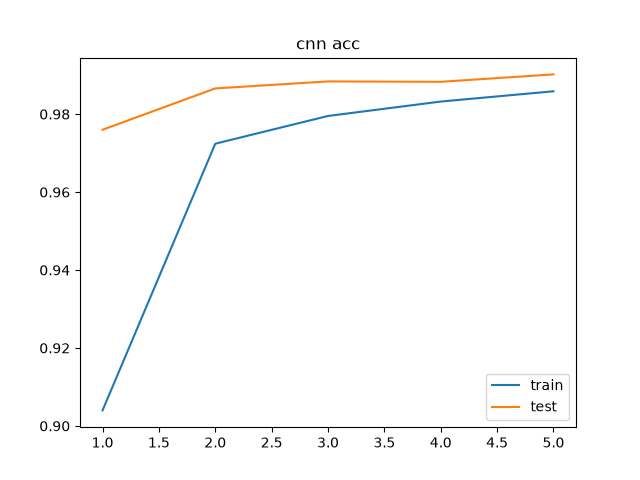

In [5]:
cnn = json.load(open('results/cnn.json'))
print('device used:', cnn['device'])
display(pd.DataFrame(cnn['history']).round(4))
display(Image('figures/curves_cnn_loss.png'))
display(Image('figures/curves_cnn_acc.png'))

The CNN converges in 2-3 epochs and reaches 99.0% test accuracy after 5 epochs, with the training and test curves staying together (no real over-fitting; dropout is active during training, so the training accuracy is even slightly lower than the test accuracy). Remaining errors are visually close digits (4/9, 3/5, 7/1).

## 3. Faster R-CNN (a detector used as a classifier)
Faster R-CNN cannot classify a bare image: it needs boxes. Each MNIST image is therefore turned into a detection sample: the ground-truth box is the tight rectangle around the ink pixels (threshold 0.1) and the class is `digit + 1` with `num_classes = 11` (0 = background). The grayscale image is repeated to 3 channels and resized to 64x64. At inference the highest-scoring box gives the digit; if no box is produced the image counts as background, i.e. an error.

Training used only **2 000 images for 1 epoch** and evaluation **1 000 test images** because the detector is much heavier than the CNN. The training loss is the sum of the four detection losses, so it is not comparable to a cross-entropy, and no test loss is reported (N/A).

In [6]:
fr = json.load(open('results/frcnn.json'))
print('device used:', fr['device'], '| detection loss:', round(fr['history'][0]['train_loss'], 4))
display(pd.read_csv('results/results_all.csv').round(4))

device used: cpu | detection loss: 3.0439


,Model,Accuracy,F1,Loss,TrainTime(s),Params,TrainImgs,TestImgs,Epochs,Device
0,CNN,0.9902,0.9901,0.0293,324.9498,421642,60000,10000,5,cpu
1,Faster R-CNN,0.7680,0.7198,NaN,98.2104,18976354,2000,1000,1,cpu
2,VGG16,0.7880,0.7881,NaN,270.5914,134301514,5000,2000,1,cpu
3,AlexNet,0.8665,0.8680,NaN,58.8627,57044810,5000,2000,1,cpu
4,ViT,0.8401,0.8399,NaN,39.1988,139018,20000,10000,3,cpu


The detector reaches only **76.8%** accuracy here (macro F1 0.72) with 2 000 training images, and each prediction is far more expensive: hundreds of region proposals, ROI pooling and box regression for a single centred digit. MNIST has nothing to localise, so all that machinery is pure overhead. Faster R-CNN is the right tool when an image contains several objects at unknown positions, not for a pre-cropped digit.

## 4. Fine-tuning VGG16 and AlexNet
ImageNet-pretrained models: input resized to 64x64, grayscale repeated to 3 channels, ImageNet normalisation, convolutional `features` frozen, only the classifier's last layer retrained (`Linear(4096, 10)`). Adam lr=1e-3, 1 epoch on 5 000 training images, evaluation on 2 000 test images.

In [7]:
import torch.nn as nn
from torchvision import transforms, models
from src.data import RepeatChannels

vgg = models.vgg16(weights=None)   # the script loads VGG16_Weights.IMAGENET1K_V1
for p in vgg.features.parameters(): p.requires_grad = False
vgg.classifier[6] = nn.Linear(4096, 10)
print('trainable parameters:', f"{sum(p.numel() for p in vgg.parameters() if p.requires_grad):,}")
print(transforms.Compose([transforms.Resize((64, 64)), transforms.ToTensor(),
                          transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
                          transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))]))

trainable parameters: 119,586,826
Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Lambda()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


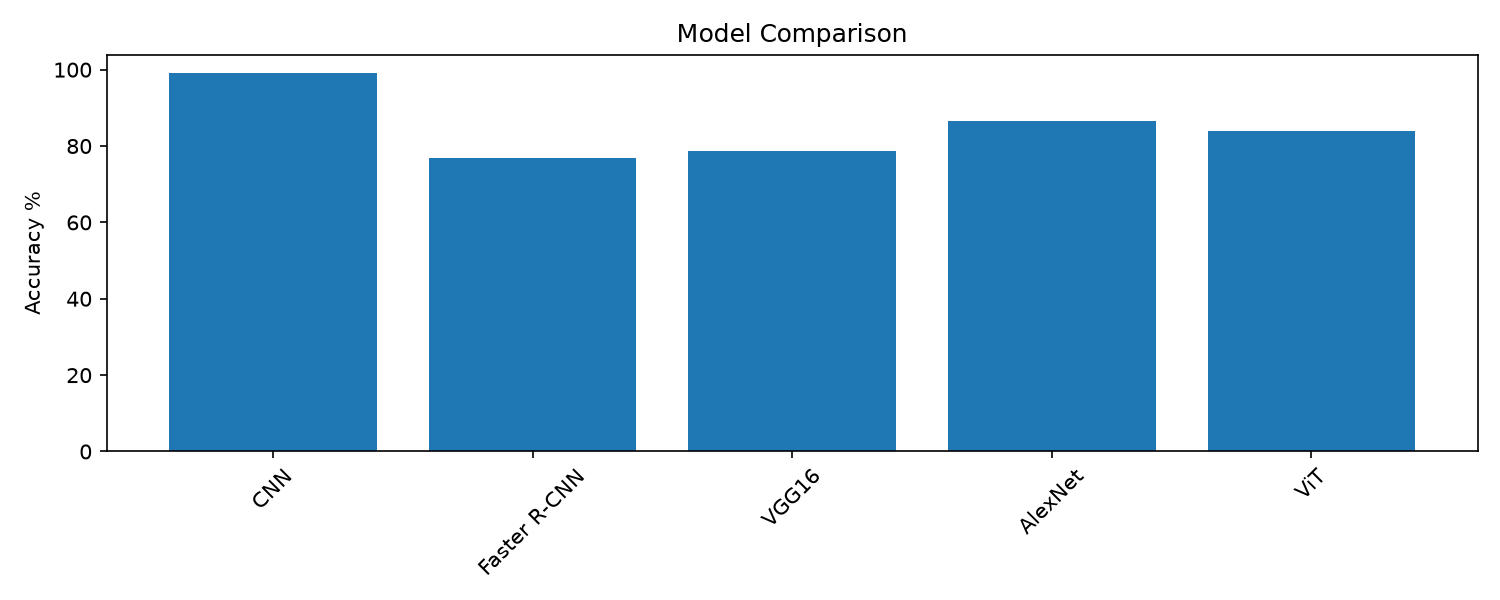

In [8]:
display(Image('figures/comparison.png'))

## 5. Conclusion
The small CNN is clearly the best choice for MNIST: **99.0% accuracy and F1**, 0.42 M parameters and a few minutes of CPU training. The fine-tuned ImageNet models reach 78.8% (VGG16) and 86.7% (AlexNet) after one epoch on 5 000 images - ImageNet filters are tuned for natural RGB textures, not for binary digit strokes, and the frozen backbone cannot adapt. Transfer learning is not worth it on MNIST, but the experiment shows the mechanics (new head, frozen features, new normalisation) that do pay off on small natural-image datasets. Faster R-CNN is by far the slowest and least accurate here because the task does not need detection at all.